# Fase 3 - Modelado supervisado de rezago escolar

Comparación de Regresión Logística, CART, Random Forest, LightGBM, XGBoost y CatBoost mediante partición independiente y `GroupKFold` por conglomerado. Todo el preprocesamiento se ajusta exclusivamente dentro de cada fold de entrenamiento.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config
from src.supervised import FEATURES, ejecutar_fase3
print('Proyecto:', ROOT)
print('Semilla:', config.RANDOM_STATE)

Proyecto: C:\Users\Jalea\Documents\U\C8\inteligencia_artificial\u2_ex\proyecto_ia
Semilla: 42


## 1. Población evaluable y protocolo anti-fuga

In [2]:
df = pd.read_parquet(config.DATASET_FINAL_PARQUET)
evaluable = df[df[config.TARGET_REZAGO].notna()]
print(f'Estudiantes evaluables: {len(evaluable):,}')
print('Distribución del target:')
display(evaluable[config.TARGET_REZAGO].value_counts().rename_axis('clase').to_frame('n'))
print(f'Conglomerados: {evaluable[config.GRUPO_CONGLOME].nunique():,}')
print('Variables predictoras:', len(FEATURES))

Estudiantes evaluables: 9,382
Distribución del target:


,n
clase,
0,8862
1,520


Conglomerados: 4,054
Variables predictoras: 19


Las variables que definen directamente el rezago (`edad`, `nivel`, `grado` y `edad_normativa`) se excluyen de los predictores. El test contiene conglomerados completamente distintos al entrenamiento.

## 2. Resultados reproducibles de entrenamiento

In [3]:
# Para volver a entrenar todos los modelos, descomente:
# resultados = ejecutar_fase3(df)
resultados = {
    'cv_folds': pd.read_csv(config.REPORTS_DIR / 'modelos_cv_folds.csv'),
    'cv_summary': pd.read_csv(config.REPORTS_DIR / 'modelos_cv_resumen.csv'),
    'test_metrics': pd.read_csv(config.REPORTS_DIR / 'modelos_metricas_test.csv'),
}
metadata = json.loads((config.REPORTS_DIR / 'modelos_metadata.json').read_text(encoding='utf-8'))
print('Campeón:', metadata['modelo_campeon'])
print('Mejor árbol para SHAP:', metadata['mejor_modelo_arbol_para_xai'])
print('Conglomerados compartidos:', metadata['conglomerados_compartidos'])

Campeón: CatBoost
Mejor árbol para SHAP: CatBoost
Conglomerados compartidos: 0


## 3. Validación cruzada agrupada

In [4]:
resultados['cv_summary'].sort_values('pr_auc_media', ascending=False).style.format(precision=4)

,modelo,roc_auc_media,pr_auc_media,f1_macro_media,f1_positivo_media,precision_media,recall_media,brier_media,roc_auc_std,pr_auc_std,f1_macro_std,f1_positivo_std,precision_std,recall_std,brier_std
0,CatBoost,0.6326,0.0937,0.4975,0.1516,0.0913,0.4466,0.1694,0.0105,0.0178,0.0033,0.0136,0.0079,0.0492,0.0067
1,Random Forest,0.6279,0.0912,0.5189,0.0780,0.1056,0.0627,0.0868,0.0192,0.0198,0.0191,0.0392,0.0446,0.0337,0.0038
2,XGBoost,0.6264,0.0887,0.5038,0.1437,0.0891,0.3722,0.1584,0.0170,0.0137,0.0081,0.0129,0.0086,0.0284,0.0039
3,Regresion Logistica,0.6168,0.0846,0.3890,0.1250,0.0689,0.6734,0.2638,0.0673,0.0261,0.0113,0.0175,0.0094,0.1144,0.0051
4,LightGBM,0.6131,0.0844,0.5151,0.1175,0.0834,0.2005,0.1136,0.0130,0.0177,0.0149,0.0269,0.0186,0.0535,0.0049
5,Arbol CART,0.5735,0.0656,0.3364,0.1111,0.0614,0.6776,0.2356,0.0381,0.0020,0.0976,0.0051,0.0013,0.2675,0.0104


## 4. Evaluación en el conjunto de prueba independiente

In [5]:
resultados['test_metrics'].sort_values('pr_auc', ascending=False).style.format(precision=4)

,modelo,roc_auc,pr_auc,f1_macro,f1_positivo,precision,recall,brier
0,XGBoost,0.5951,0.1068,0.4904,0.1363,0.0866,0.3200,0.1677
1,Regresion Logistica,0.6196,0.1055,0.4046,0.1518,0.0855,0.6720,0.2595
2,CatBoost,0.5969,0.1048,0.4855,0.1463,0.0904,0.3840,0.1803
3,Random Forest,0.5973,0.0939,0.5170,0.0787,0.1321,0.0560,0.0941
4,LightGBM,0.5637,0.0902,0.5247,0.1429,0.1067,0.2160,0.1280
5,Arbol CART,0.6001,0.0820,0.5092,0.1541,0.1007,0.3280,0.2377


## 5. Curvas ROC/PR, calibración y matriz de confusión

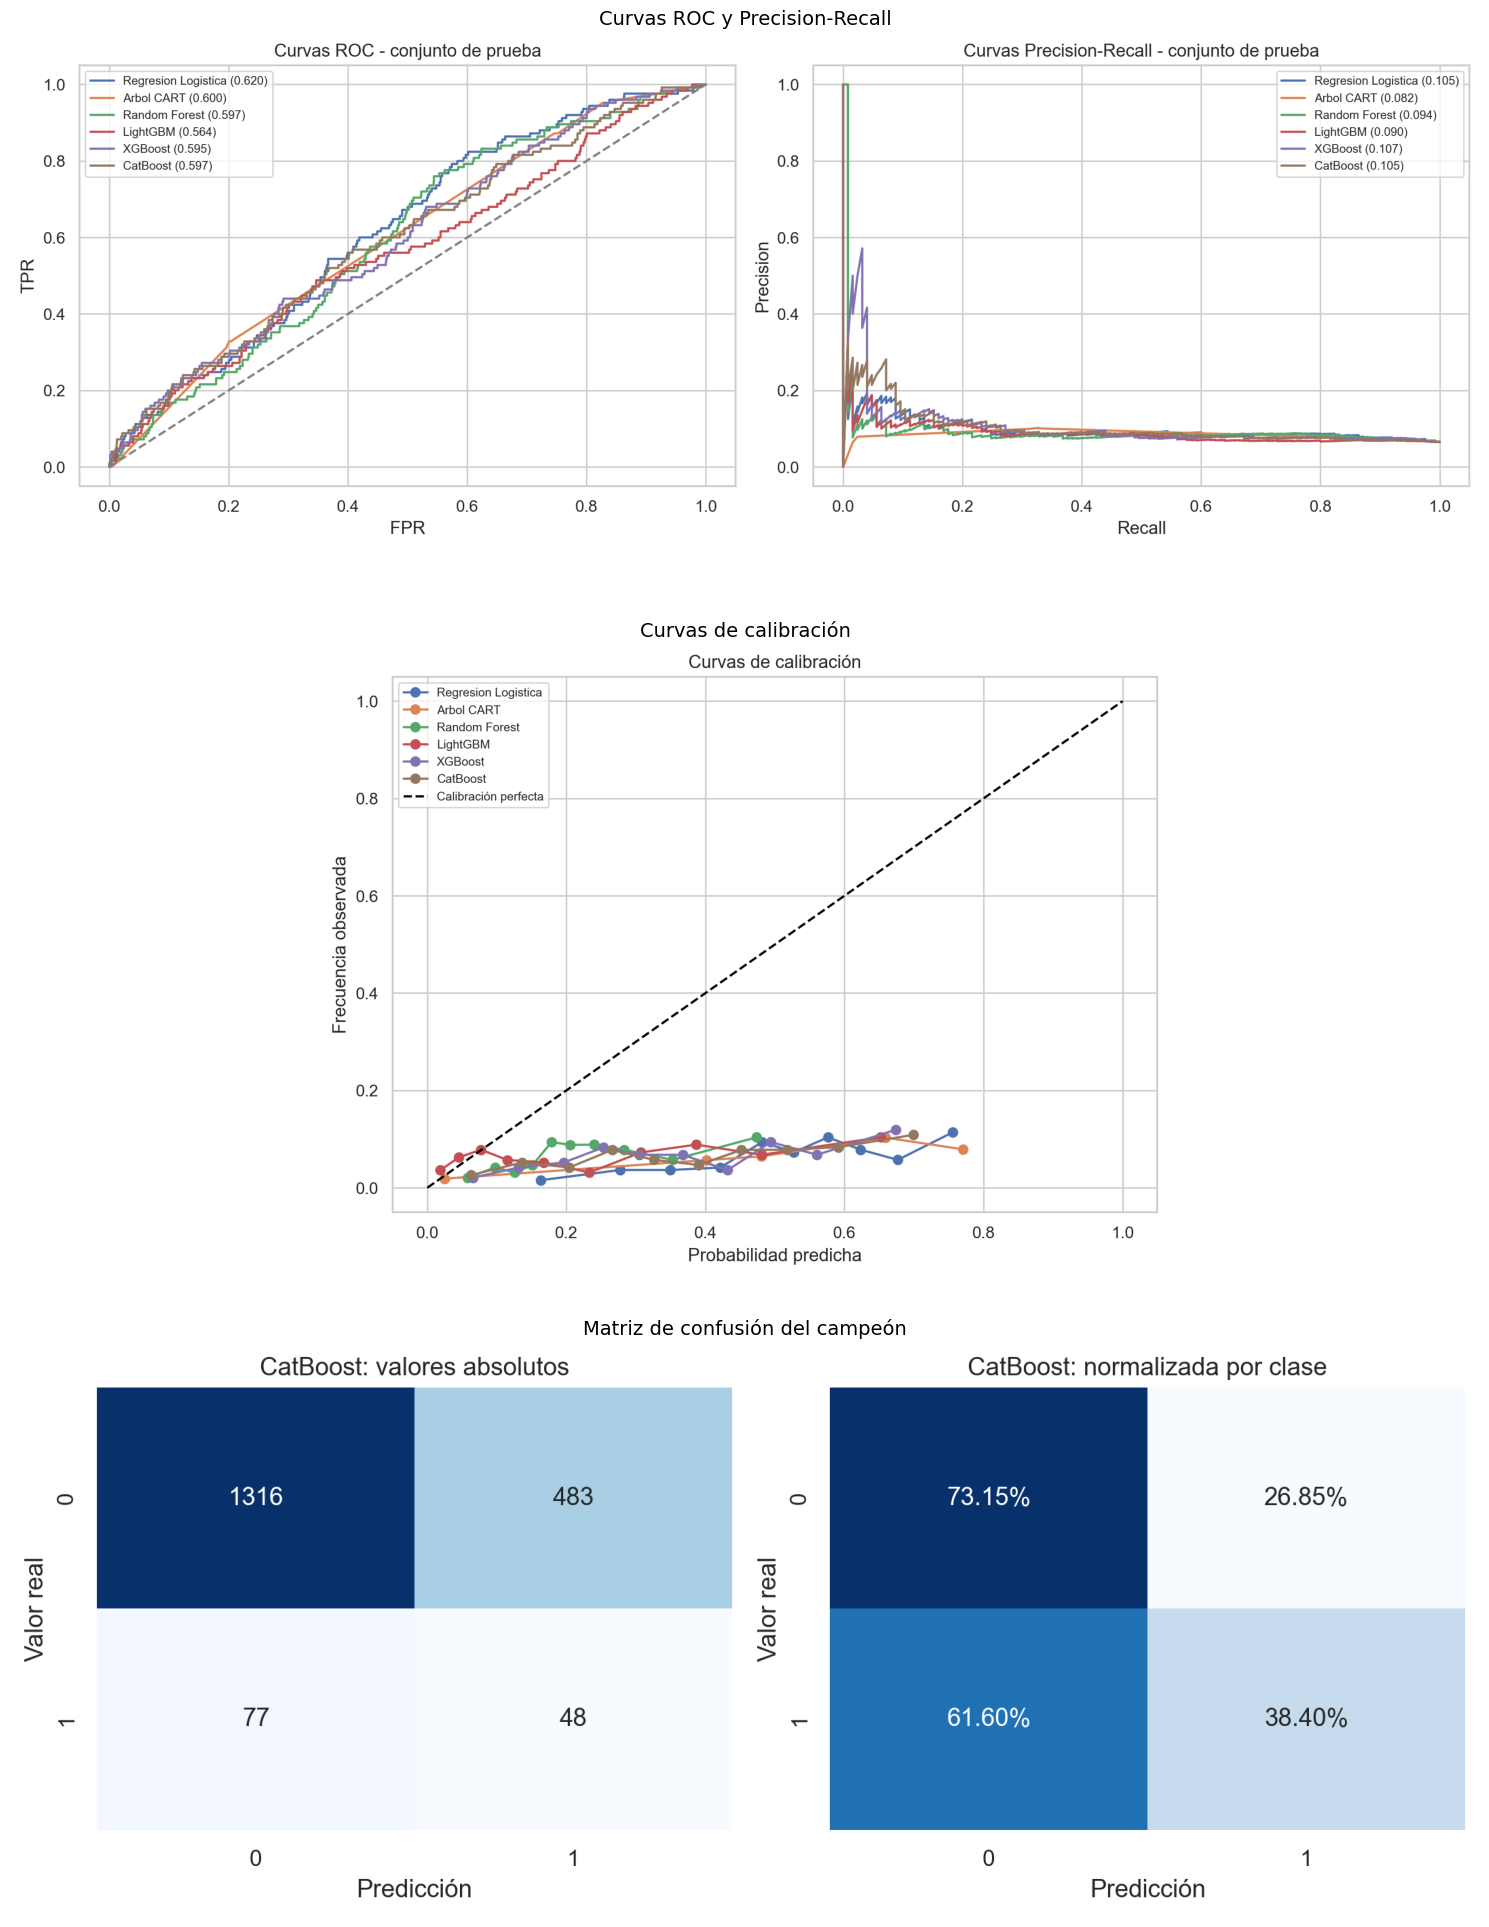

In [6]:
names = ['modelos_curvas_roc_pr.png', 'modelos_calibracion.png', 'modelo_campeon_matriz_confusion.png']
titles = ['Curvas ROC y Precision-Recall', 'Curvas de calibración', 'Matriz de confusión del campeón']
fig, axes = plt.subplots(3, 1, figsize=(15, 20))
for ax, name, title in zip(axes, names, titles):
    ax.imshow(plt.imread(config.FIGURES_DIR / name))
    ax.set_title(title, fontsize=14)
    ax.axis('off')
plt.tight_layout()

## Conclusiones de la Fase 3

CatBoost obtuvo el mayor PR-AUC promedio en GroupKFold (0.094) y fue seleccionado como campeón; XGBoost alcanzó el mayor PR-AUC puntual en prueba (0.107). La capacidad predictiva es moderada y la ponderación de clases incrementa el recall a costa de falsos positivos y sobreestimación de probabilidades. CatBoost se conserva para SHAP TreeExplainer en la Fase 4.